In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/manish8101/mobile-sales-dataset/Mobile_Sales_Dataset.xlsx


In [2]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

In [3]:
# 2. LOAD DATASET
files = glob.glob(
    "/kaggle/input/datasets/manish8101/mobile-sales-dataset/Mobile_Sales_Dataset.xlsx",
    recursive=True
)

if not files:
    raise FileNotFoundError(
        "Mobile_Sales_Dataset.xlsx not found. "
        "Please attach the dataset to Kaggle."
    )

FILE_PATH = files[0]

# Read Sales sheet
df = pd.read_excel(
    FILE_PATH,
    sheet_name="Sales"
)

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset Shape: (3114, 11)

First 5 Records:


,Brands,Models,Colors,Mobile,Memory,Storage,Selling Price,Original Price,Discount,Rating,R
0,SAMSUNG,GALAXY M31S,Mirage Black,SAMSUNG GALAXY M31S,8,128,19330,20999,1669,4.3,5
1,Nokia,3.2,Steel,Nokia 3.2,2,16,10199,10199,0,3.8,4
2,realme,C2,Diamond Black,realme C2,2,89,6999,7999,1000,4.4,5
3,Infinix,Note 5,Ice Blue,Infinix Note 5,4,64,12999,12999,0,4.2,5
4,Apple,iPhone 11,Black,Apple iPhone 11,4,64,49900,49900,0,4.6,5



Column Names:
['Brands', 'Models', 'Colors', 'Mobile', 'Memory', 'Storage', 'Selling Price', 'Original Price', 'Discount', 'Rating', 'R']


`Dataset Overview`

In [4]:
print("DATASET INFORMATION")
print("=" * 50)

print("\nShape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nUnique Brands:")
print(df["Brands"].nunique())

print("\nUnique Models:")
print(df["Models"].nunique())

print("\nBrand Distribution:")
display(df["Brands"].value_counts())

DATASET INFORMATION

Shape:
(3114, 11)

Data Types:
Brands             object
Models             object
Colors             object
Mobile             object
Memory             object
Storage             int64
Selling Price       int64
Original Price      int64
Discount            int64
Rating            float64
R                   int64
dtype: object

Missing Values:
Brands            0
Models            0
Colors            0
Mobile            0
Memory            0
Storage           0
Selling Price     0
Original Price    0
Discount          0
Rating            0
R                 0
dtype: int64

Duplicate Records:
108

Statistical Summary:


,Brands,Models,Colors,Mobile,Memory,Storage,Selling Price,Original Price,Discount,Rating,R
count,3114,3114,3114,3114,3114.0,3114.000000,3114.000000,3114.000000,3114.000000,3114.000000,3114.000000
unique,17,913,639,927,22.0,NaN,NaN,NaN,NaN,NaN,NaN
top,SAMSUNG,iPhone 11,Black,Apple iPhone 11,4.0,NaN,NaN,NaN,NaN,NaN,NaN
freq,719,36,489,36,926.0,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,88.831407,26436.625562,28333.473025,1896.847463,4.241105,4.801220
std,NaN,NaN,NaN,NaN,NaN,92.229271,30066.892622,31525.599889,5337.126176,0.265780,0.409475
min,NaN,NaN,NaN,NaN,NaN,1.000000,1000.000000,1000.000000,-8000.000000,2.300000,3.000000
25%,NaN,NaN,NaN,NaN,NaN,32.000000,9990.000000,10030.250000,0.000000,4.100000,5.000000
50%,NaN,NaN,NaN,NaN,NaN,64.000000,15000.000000,16889.500000,0.000000,4.300000,5.000000
75%,NaN,NaN,NaN,NaN,NaN,128.000000,28999.000000,31500.000000,2000.000000,4.400000,5.000000



Unique Brands:
17

Unique Models:
913

Brand Distribution:


Brands
SAMSUNG         719
Apple           387
realme          327
OPPO            260
Nokia           213
Xiaomi          198
Infinix         151
GIONEE          129
vivo            124
Lenovo          121
ASUS            118
Motorola        105
LG               99
POCO             74
HTC              55
Google Pixel     29
IQOO              5
Name: count, dtype: int64

`Data Cleaning & Preprocess`

In [5]:
mobile = df.copy()

# Remove exact duplicate records
mobile = mobile.drop_duplicates().copy()

# Clean text columns
text_columns = [
    "Brands",
    "Models",
    "Colors",
    "Mobile"
]

for col in text_columns:

    mobile[col] = (
        mobile[col]
        .astype(str)
        .str.strip()
    )

# Convert numeric columns
numeric_columns = [
    "Memory",
    "Storage",
    "Selling Price",
    "Original Price",
    "Discount",
    "Rating"
]

for col in numeric_columns:

    mobile[col] = pd.to_numeric(
        mobile[col],
        errors="coerce"
    )

# Remove records with missing essential values
mobile = mobile.dropna(
    subset=[
        "Brands",
        "Models",
        "Memory",
        "Storage",
        "Selling Price",
        "Original Price",
        "Rating"
    ]
).copy()

# Remove invalid values
mobile = mobile[
    (mobile["Selling Price"] > 0) &
    (mobile["Original Price"] > 0) &
    (mobile["Memory"] > 0) &
    (mobile["Storage"] > 0) &
    (mobile["Rating"] >= 0) &
    (mobile["Rating"] <= 5)
].copy()

# Calculate actual discount from prices
mobile["Calculated_Discount"] = (
    mobile["Original Price"] -
    mobile["Selling Price"]
)

# Calculate discount percentage
mobile["Discount_Percentage"] = np.where(
    mobile["Original Price"] > 0,
    mobile["Calculated_Discount"] /
    mobile["Original Price"] * 100,
    0
)

# Flag records with unusual discount information
mobile["Discount_Flag"] = np.where(
    mobile["Calculated_Discount"] < 0,
    "Price Above Original",
    np.where(
        mobile["Calculated_Discount"] > 0,
        "Discount Available",
        "No Discount"
    )
)

# Keep unusual records but identify them
mobile["Memory_Flag"] = np.where(
    mobile["Memory"] > 18,
    "Check MB or unusual value",
    "Normal GB range"
)

print("Data cleaning completed!")

print("\nCleaned Dataset Shape:", mobile.shape)

print("\nMissing Values:")
print(mobile.isnull().sum())

print("\nDiscount Information:")
display(mobile["Discount_Flag"].value_counts())

print("\nCleaned Dataset:")
display(mobile.head())

Data cleaning completed!

Cleaned Dataset Shape: (3005, 15)

Missing Values:
Brands                 0
Models                 0
Colors                 0
Mobile                 0
Memory                 0
Storage                0
Selling Price          0
Original Price         0
Discount               0
Rating                 0
R                      0
Calculated_Discount    0
Discount_Percentage    0
Discount_Flag          0
Memory_Flag            0
dtype: int64

Discount Information:


Discount_Flag
No Discount             1847
Discount Available      1157
Price Above Original       1
Name: count, dtype: int64


Cleaned Dataset:


,Brands,Models,Colors,Mobile,Memory,Storage,Selling Price,Original Price,Discount,Rating,R,Calculated_Discount,Discount_Percentage,Discount_Flag,Memory_Flag
0,SAMSUNG,GALAXY M31S,Mirage Black,SAMSUNG GALAXY M31S,8.0,128,19330,20999,1669,4.3,5,1669,7.947998,Discount Available,Normal GB range
1,Nokia,3.2,Steel,Nokia 3.2,2.0,16,10199,10199,0,3.8,4,0,0.000000,No Discount,Normal GB range
2,realme,C2,Diamond Black,realme C2,2.0,89,6999,7999,1000,4.4,5,1000,12.501563,Discount Available,Normal GB range
3,Infinix,Note 5,Ice Blue,Infinix Note 5,4.0,64,12999,12999,0,4.2,5,0,0.000000,No Discount,Normal GB range
4,Apple,iPhone 11,Black,Apple iPhone 11,4.0,64,49900,49900,0,4.6,5,0,0.000000,No Discount,Normal GB range


`Normalize memory and storage information`

In [6]:
# 5. MEMORY NORMALIZATION

mobile["Memory_GB"] = np.where(
    mobile["Memory"] > 18,
    mobile["Memory"] / 1024,
    mobile["Memory"]
)

# Create readable categories
mobile["Memory_Category"] = (
    mobile["Memory_GB"].round(2).astype(str) + " GB"
)

mobile["Storage_Category"] = (
    mobile["Storage"].astype(str) + " GB"
)

print("Memory normalization completed!")

display(
    mobile[
        [
            "Brands",
            "Models",
            "Memory",
            "Memory_GB",
            "Memory_Category",
            "Storage"
        ]
    ].head(15)
)

Memory normalization completed!


,Brands,Models,Memory,Memory_GB,Memory_Category,Storage
0,SAMSUNG,GALAXY M31S,8.0,8.0,8.0 GB,128
1,Nokia,3.2,2.0,2.0,2.0 GB,16
2,realme,C2,2.0,2.0,2.0 GB,89
3,Infinix,Note 5,4.0,4.0,4.0 GB,64
4,Apple,iPhone 11,4.0,4.0,4.0 GB,64
5,GIONEE,L800,8.0,8.0,8.0 GB,16
6,Apple,iPhone 13 Mini,6.0,6.0,6.0 GB,512
7,Apple,iPhone XR,3.0,3.0,3.0 GB,64
8,SAMSUNG,Galaxy E5,1.5,1.5,1.5 GB,16
9,Xiaomi,Redmi Note 11T 5G,8.0,8.0,8.0 GB,128


`Solved Questions`

# 1. Which mobile brand has the highest number of mobile models in the dataset? 

In [7]:
brand_models = mobile.groupby("Brands").agg(

    Total_Models=("Models", "nunique"),

    Total_Records=("Models", "count")

).reset_index()

brand_models = brand_models.sort_values(
    "Total_Models",
    ascending=False
)

print("MOBILE MODELS BY BRAND")

display(brand_models)

print("\nBrand with highest number of models:")

display(brand_models.head(1))

MOBILE MODELS BY BRAND


,Brands,Total_Models,Total_Records
13,SAMSUNG,210,704
10,Nokia,83,199
11,OPPO,77,257
7,LG,64,99
15,realme,62,322
2,GIONEE,60,128
16,vivo,59,124
8,Lenovo,55,116
9,Motorola,50,104
14,Xiaomi,49,198



Brand with highest number of models:


,Brands,Total_Models,Total_Records
13,SAMSUNG,210,704


# 2. Which are the top 10 mobile models based on their selling price? 

In [8]:
top_10_expensive = mobile.groupby(
    ["Brands", "Models"]
).agg(

    Average_Selling_Price=("Selling Price", "mean"),

    Maximum_Selling_Price=("Selling Price", "max"),

    Average_Rating=("Rating", "mean"),

    Available_Records=("Models", "count")

).reset_index()

top_10_expensive = top_10_expensive.sort_values(
    "Average_Selling_Price",
    ascending=False
).head(10)

print("TOP 10 EXPENSIVE MODELS")

display(top_10_expensive)

TOP 10 EXPENSIVE MODELS


,Brands,Models,Average_Selling_Price,Maximum_Selling_Price,Average_Rating,Available_Records
544,SAMSUNG,Fold 2 5G,169999.000000,169999,4.200000,1
43,Apple,iPhone 13 Pro Max,152602.702703,179900,4.451351,37
710,SAMSUNG,Galaxy Z Fold3 5G,151999.000000,157999,4.400000,4
604,SAMSUNG,Galaxy Fold 2,149999.000000,149999,3.000000,2
42,Apple,iPhone 13 Pro,148361.538462,169900,4.238462,13
39,Apple,iPhone 12 Pro Max,133233.333333,149900,4.600000,12
35,Apple,iPhone 11 Pro Max,131672.727273,150800,4.700000,11
38,Apple,iPhone 12 Pro,121718.181818,139900,4.600000,11
688,SAMSUNG,Galaxy S21 Ultra,109665.666667,116999,4.433333,3
34,Apple,iPhone 11 Pro,104062.000000,140300,4.600000,16


# 3. What is the average selling price of mobiles for each brand? 

In [9]:
brand_price = mobile.groupby("Brands").agg(

    Average_Selling_Price=("Selling Price", "mean"),

    Minimum_Price=("Selling Price", "min"),

    Maximum_Price=("Selling Price", "max"),

    Total_Models=("Models", "nunique")

).reset_index()

brand_price = brand_price.sort_values(
    "Average_Selling_Price",
    ascending=False
)

print("AVERAGE PRICE BY BRAND")

display(brand_price)

AVERAGE PRICE BY BRAND


,Brands,Average_Selling_Price,Minimum_Price,Maximum_Price,Total_Models
1,Apple,85963.077160,24999,179900,25
3,Google Pixel,61391.862069,12000,92000,11
5,IQOO,37190.000000,34990,39990,1
4,HTC,28314.381818,6999,62990,29
13,SAMSUNG,24248.139205,1099,169999,210
16,vivo,23866.241935,7990,79990,59
0,ASUS,20367.324786,4499,79999,33
7,LG,19323.181818,5000,60000,64
11,OPPO,18493.178988,4999,60990,77
14,Xiaomi,16941.909091,6499,54999,49


# 4. Which mobile brand offers the highest average discount? 

In [10]:
brand_discount = mobile.groupby("Brands").agg(

    Average_Discount=("Calculated_Discount", "mean"),

    Average_Discount_Percentage=(
        "Discount_Percentage", "mean"
    ),

    Total_Models=("Models", "nunique")

).reset_index()

brand_discount = brand_discount.sort_values(
    "Average_Discount",
    ascending=False
)

print("BRAND-WISE DISCOUNT")

display(brand_discount)

print("\nHighest Average Discount Amount:")

display(brand_discount.head(1))

print("\nHighest Average Discount Percentage:")

display(
    brand_discount.sort_values(
        "Average_Discount_Percentage",
        ascending=False
    ).head(1)
)

BRAND-WISE DISCOUNT


,Brands,Average_Discount,Average_Discount_Percentage,Total_Models
9,Motorola,4288.548077,12.538830,50
5,IQOO,3800.000000,9.065627,1
7,LG,3044.595960,8.718038,64
1,Apple,2874.033951,3.533866,25
12,POCO,2614.864865,14.346840,14
13,SAMSUNG,2549.796875,5.841892,210
11,OPPO,2063.042802,8.588911,77
16,vivo,1696.661290,5.675480,59
15,realme,1437.586957,8.671248,62
0,ASUS,1269.230769,1.817493,33



Highest Average Discount Amount:


,Brands,Average_Discount,Average_Discount_Percentage,Total_Models
9,Motorola,4288.548077,12.53883,50



Highest Average Discount Percentage:


,Brands,Average_Discount,Average_Discount_Percentage,Total_Models
12,POCO,2614.864865,14.34684,14


# 5. Which mobile brands have the highest average customer rating, and how does their average selling price compare? 

In [11]:
brand_rating = mobile.groupby("Brands").agg(

    Average_Rating=("Rating", "mean"),

    Average_Selling_Price=("Selling Price", "mean"),

    Total_Models=("Models", "nunique"),

    Total_Records=("Rating", "count")

).reset_index()

brand_rating = brand_rating.sort_values(
    "Average_Rating",
    ascending=False
)

print("BRAND-WISE CUSTOMER RATINGS")

display(brand_rating)

print("\nTop 5 Highest Rated Brands:")

display(brand_rating.head(5))

BRAND-WISE CUSTOMER RATINGS


,Brands,Average_Rating,Average_Selling_Price,Total_Models,Total_Records
1,Apple,4.507716,85963.077160,25,324
3,Google Pixel,4.506897,61391.862069,11,29
5,IQOO,4.400000,37190.000000,1,5
12,POCO,4.385135,16870.621622,14,74
15,realme,4.381677,16261.403727,62,322
16,vivo,4.370968,23866.241935,59,124
14,Xiaomi,4.301515,16941.909091,49,198
11,OPPO,4.293774,18493.178988,77,257
6,Infinix,4.276000,11099.466667,40,150
13,SAMSUNG,4.208381,24248.139205,210,704



Top 5 Highest Rated Brands:


,Brands,Average_Rating,Average_Selling_Price,Total_Models,Total_Records
1,Apple,4.507716,85963.077160,25,324
3,Google Pixel,4.506897,61391.862069,11,29
5,IQOO,4.400000,37190.000000,1,5
12,POCO,4.385135,16870.621622,14,74
15,realme,4.381677,16261.403727,62,322


#. How does mobile storage capacity affect the average selling price? Can you compare mobiles with different storage options?

In [12]:
storage_analysis = mobile.groupby("Storage").agg(

    Average_Selling_Price=("Selling Price", "mean"),

    Minimum_Price=("Selling Price", "min"),

    Maximum_Price=("Selling Price", "max"),

    Average_Rating=("Rating", "mean"),

    Total_Mobiles=("Models", "count")

).reset_index()

# Ignore storage categories with very few records
storage_analysis = storage_analysis[
    storage_analysis["Total_Mobiles"] >= 5
]

storage_analysis = storage_analysis.sort_values(
    "Storage"
)

print("STORAGE CAPACITY ANALYSIS")

display(storage_analysis)

STORAGE CAPACITY ANALYSIS


,Storage,Average_Selling_Price,Minimum_Price,Maximum_Price,Average_Rating,Total_Mobiles
0,1,171906.428571,117990,179900,4.400000,14
1,2,2059.953488,1099,4790,4.162791,43
2,4,5665.154762,1000,17200,3.917857,84
3,8,8123.289855,1600,35490,3.895652,138
5,16,12224.744745,1099,72000,4.045345,333
6,32,14190.230909,2200,59590,4.172545,550
8,64,20665.442971,2790,117100,4.288859,754
9,89,26331.076923,6999,179900,4.338462,39
11,128,30190.469415,2490,129900,4.326995,752
16,256,66223.220721,1662,169999,4.428829,222


# 7. Which mobile models provide the highest discount amount, and what percentage of their original price is discounted? 

In [13]:
top_discount_models = mobile.sort_values(
    "Calculated_Discount",
    ascending=False
).head(10)

print("TOP 10 DISCOUNTED MOBILES")

display(
    top_discount_models[
        [
            "Brands",
            "Models",
            "Original Price",
            "Selling Price",
            "Calculated_Discount",
            "Discount_Percentage",
            "Rating"
        ]
    ]
)

TOP 10 DISCOUNTED MOBILES


,Brands,Models,Original Price,Selling Price,Calculated_Discount,Discount_Percentage,Rating
711,Motorola,Razr,149999,74999,75000,50.000333,3.8
589,Motorola,Razr,149999,74999,75000,50.000333,3.8
848,Motorola,Razr 5G,149999,89999,60000,40.000267,4.0
306,ASUS,ROG,83999,26499,57500,68.453196,4.3
507,LG,Wing,80000,29999,50001,62.501250,4.2
2632,LG,Wing,80000,29999,50001,62.501250,4.2
1428,Apple,iPhone XS Max,124900,78999,45901,36.750200,4.6
911,Apple,iPhone XS Max,124900,78999,45901,36.750200,4.6
410,Apple,iPhone XS Max,124900,78999,45901,36.750200,4.6
1482,LG,G8X,70000,27990,42010,60.014286,4.4


# 8. Which combination of memory and storage offers the best balance between selling price and customer rating? 

In [14]:
memory_storage = mobile.groupby(
    ["Memory_Category", "Storage_Category"]
).agg(

    Average_Selling_Price=("Selling Price", "mean"),

    Average_Rating=("Rating", "mean"),

    Total_Mobiles=("Models", "count")

).reset_index()

# Keep combinations with sufficient records
memory_storage = memory_storage[
    memory_storage["Total_Mobiles"] >= 5
].copy()

# Normalize price and rating
memory_storage["Price_Score"] = (
    memory_storage["Average_Selling_Price"]
    .rank(pct=True, ascending=False)
)

memory_storage["Rating_Score"] = (
    memory_storage["Average_Rating"]
    .rank(pct=True, ascending=True)
)

# Equal weight for price affordability and rating
memory_storage["Balance_Score"] = (

    0.50 * memory_storage["Price_Score"] +

    0.50 * memory_storage["Rating_Score"]

)

memory_storage = memory_storage.sort_values(
    "Balance_Score",
    ascending=False
)

print("BEST MEMORY + STORAGE COMBINATION")

display(memory_storage.head(10))

print("\nBest combination:")

display(memory_storage.head(1))

BEST MEMORY + STORAGE COMBINATION


,Memory_Category,Storage_Category,Average_Selling_Price,Average_Rating,Total_Mobiles,Price_Score,Rating_Score,Balance_Score
68,4.0 GB,2 GB,2151.166667,4.216667,6,0.938776,0.448980,0.693878
37,14.0 GB,16 GB,1945.400000,4.200000,5,0.959184,0.397959,0.678571
64,3.0 GB,89 GB,10036.400000,4.310000,10,0.734694,0.612245,0.673469
75,4.0 GB,89 GB,12998.100000,4.400000,10,0.612245,0.734694,0.673469
38,14.0 GB,2 GB,1447.117647,4.176471,17,1.000000,0.346939,0.673469
59,3.0 GB,128 GB,45449.500000,4.550000,12,0.367347,0.918367,0.642857
71,4.0 GB,4 GB,1830.857143,4.146429,28,0.979592,0.306122,0.642857
1,0.03 GB,2 GB,2605.750000,4.137500,8,0.897959,0.285714,0.591837
91,8.0 GB,512 GB,68985.142857,4.571429,7,0.224490,0.938776,0.581633
51,2.0 GB,128 GB,47476.692308,4.484615,13,0.346939,0.795918,0.571429



Best combination:


,Memory_Category,Storage_Category,Average_Selling_Price,Average_Rating,Total_Mobiles,Price_Score,Rating_Score,Balance_Score
68,4.0 GB,2 GB,2151.166667,4.216667,6,0.938776,0.44898,0.693878


# 9. Can you identify the top 10 mobile models that provide the best value for money by considering selling price, discount, storage, memory, and customer rating? Explain how you calculated the value score.

In [15]:
# Group by mobile configuration
value_data = mobile.groupby(
    ["Brands", "Models", "Memory_GB", "Storage"]
).agg(

    Average_Selling_Price=("Selling Price", "mean"),

    Average_Original_Price=("Original Price", "mean"),

    Average_Rating=("Rating", "mean"),

    Average_Discount_Percentage=(
        "Discount_Percentage", "mean"
    ),

    Total_Records=("Models", "count")

).reset_index()


# Calculate normalized scores (0 to 100)

# Lower price = higher score
value_data["Price_Score"] = (
    value_data["Average_Selling_Price"]
    .rank(pct=True, ascending=False) * 100
)

# Higher rating = higher score
value_data["Rating_Score"] = (
    value_data["Average_Rating"]
    .rank(pct=True) * 100
)

# Higher discount = higher score
value_data["Discount_Score"] = (
    value_data["Average_Discount_Percentage"]
    .rank(pct=True) * 100
)

# Higher storage = higher score
value_data["Storage_Score"] = (
    value_data["Storage"]
    .rank(pct=True) * 100
)

# Higher memory = higher score
value_data["Memory_Score"] = (
    value_data["Memory_GB"]
    .rank(pct=True) * 100
)


# Calculate Value for Money Score

value_data["VFM_Score"] = (

    0.30 * value_data["Rating_Score"] +

    0.25 * value_data["Price_Score"] +

    0.20 * value_data["Discount_Score"] +

    0.15 * value_data["Storage_Score"] +

    0.10 * value_data["Memory_Score"]

)


# Rank mobile models
value_data["VFM_Rank"] = value_data["VFM_Score"].rank(
    ascending=False,
    method="min"
).astype(int)


# Top 10 value-for-money mobiles
top_10_value = value_data.sort_values(
    "VFM_Score",
    ascending=False
).head(10)


print("TOP 10 VALUE FOR MONEY MOBILES")

display(
    top_10_value[
        [
            "VFM_Rank",
            "Brands",
            "Models",
            "Memory_GB",
            "Storage",
            "Average_Selling_Price",
            "Average_Rating",
            "Average_Discount_Percentage",
            "VFM_Score"
        ]
    ]
)

TOP 10 VALUE FOR MONEY MOBILES


,VFM_Rank,Brands,Models,Memory_GB,Storage,Average_Selling_Price,Average_Rating,Average_Discount_Percentage,VFM_Score
1135,1,realme,3,3.0,89,8499.000000,4.5,22.729339,78.758146
721,2,POCO,M2,6.0,128,11499.000000,4.4,23.334889,77.396814
1294,3,vivo,V20 2021,12.0,256,15490.000000,4.4,20.523345,77.346126
653,4,OPPO,F11 Pro,6.0,128,16990.000000,4.5,43.347783,76.736061
1353,5,vivo,Y30,8.0,128,13990.000000,4.4,26.329647,76.517017
1179,6,realme,9 5G,6.0,128,17499.000000,4.8,16.667460,76.357712
736,7,POCO,X2,6.0,128,15999.000000,4.5,20.001000,75.725923
272,8,Infinix,Note 11,6.0,128,14665.666667,4.5,13.726298,75.481535
1134,9,realme,3,3.0,64,9499.000000,4.5,20.835070,75.445329
1219,10,realme,C35,4.0,128,12999.000000,4.5,13.334222,74.867849


# 10. Can you analyze the factors that determine whether a mobile is classified as a "Good Product"? Which factors such as price, discount, rating, memory, or storage appear to have the strongest relationship with Good Product?  


In [16]:
# 1: CREATE GOOD PRODUCT COLUMN

mobile["Good_Product"] = np.where(
    mobile["Rating"] >= 4.0,
    1,
    0
)

mobile["Product_Status"] = mobile[
    "Good_Product"
].map({
    1: "Good Product",
    0: "Not Good Product"
})

print("PRODUCT CLASSIFICATION")

display(
    mobile["Product_Status"].value_counts()
)


# 2: CHECK CLASSIFICATION PERCENTAGE

product_distribution = mobile[
    "Product_Status"
].value_counts(normalize=True) * 100

print("\nProduct Classification Percentage:")

display(product_distribution)


# 3: CORRELATION ANALYSIS
#-----------------------NOTE----------------------------
# Rating is included here because it defines the target.
# Its strong relationship is expected by construction.
#-------------------------------------------------------

correlation_data = mobile[
    [
        "Selling Price",
        "Discount_Percentage",
        "Rating",
        "Memory_GB",
        "Storage",
        "Good_Product"
    ]
]

correlation_matrix = correlation_data.corr(
    numeric_only=True
)

print("\nCORRELATION WITH GOOD PRODUCT:")

display(
    correlation_matrix[["Good_Product"]].sort_values(
        "Good_Product",
        ascending=False
    )
)


# 4: RANDOM FOREST CLASSIFICATION

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Do not include Rating because it defines Good_Product
X = mobile[
    [
        "Selling Price",
        "Discount_Percentage",
        "Memory_GB",
        "Storage"
    ]
]

y = mobile["Good_Product"]


# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


# Create model
rf_model = RandomForestClassifier(

    n_estimators=200,

    random_state=42,

    class_weight="balanced",

    max_depth=8

)


# Train model
rf_model.fit(X_train, y_train)


# Predict results
y_pred = rf_model.predict(X_test)


# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("\nRANDOM FOREST RESULTS")

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not Good Product",
            "Good Product"
        ],
        zero_division=0
    )
)


# 5: FEATURE IMPORTANCE

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": rf_model.feature_importances_

})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print("\nFEATURE IMPORTANCE:")

display(feature_importance)


# 6: MOST IMPORTANT FACTOR

print("\nMOST IMPORTANT PREDICTOR:")

print(
    feature_importance.iloc[0]["Feature"]
)

PRODUCT CLASSIFICATION


Product_Status
Good Product        2611
Not Good Product     394
Name: count, dtype: int64


Product Classification Percentage:


Product_Status
Good Product        86.888519
Not Good Product    13.111481
Name: proportion, dtype: float64


CORRELATION WITH GOOD PRODUCT:


,Good_Product
Good_Product,1.000000
Rating,0.735985
Memory_GB,0.245853
Storage,0.223548
Selling Price,0.180369
Discount_Percentage,0.045145



RANDOM FOREST RESULTS
Model Accuracy: 85.19 %

Classification Report:
                  precision    recall  f1-score   support

Not Good Product       0.45      0.57      0.50        79
    Good Product       0.93      0.89      0.91       522

        accuracy                           0.85       601
       macro avg       0.69      0.73      0.71       601
    weighted avg       0.87      0.85      0.86       601


FEATURE IMPORTANCE:


,Feature,Importance
0,Selling Price,0.380539
2,Memory_GB,0.254752
3,Storage,0.236409
1,Discount_Percentage,0.128300



MOST IMPORTANT PREDICTOR:
Selling Price


# Confusion Matrix for Good Product Classification

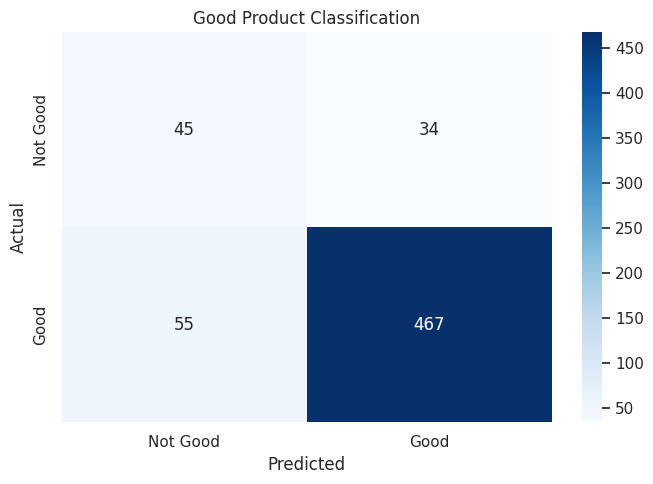

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Good",
        "Good"
    ],
    yticklabels=[
        "Not Good",
        "Good"
    ]
)

plt.title("Good Product Classification")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

# Visualize the things

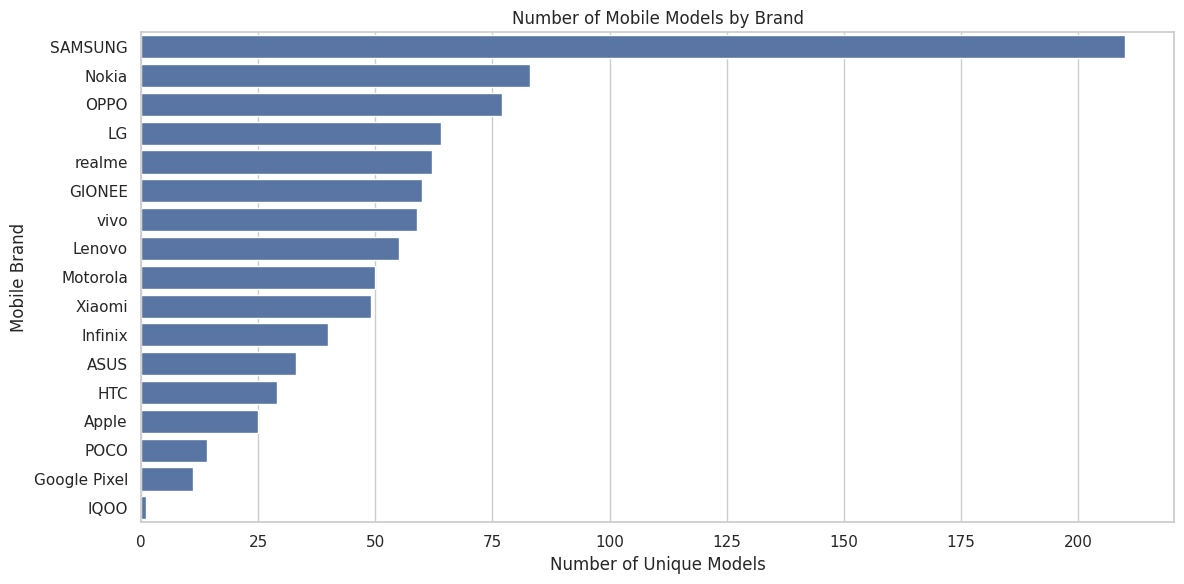

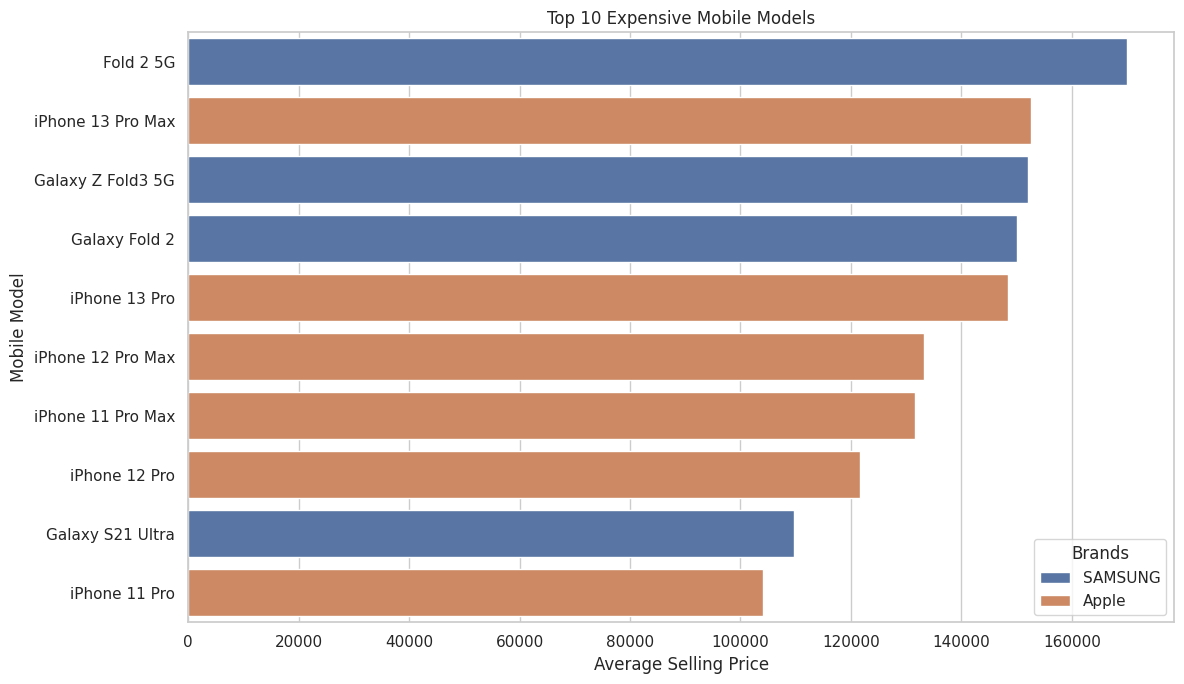

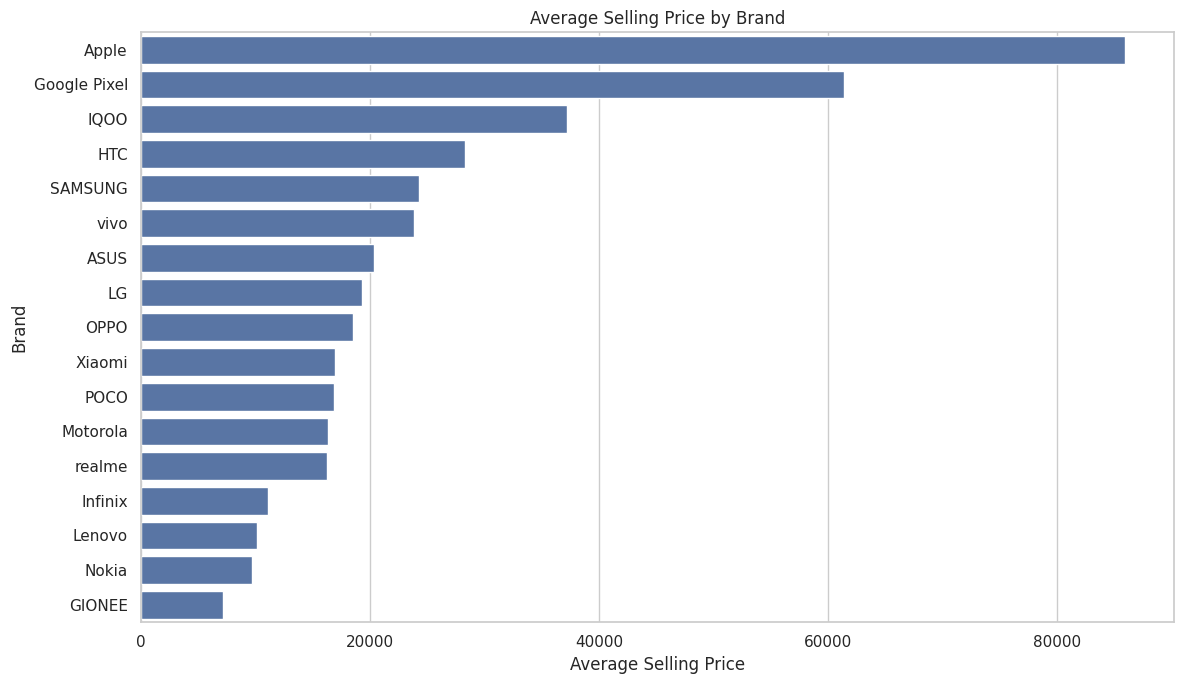

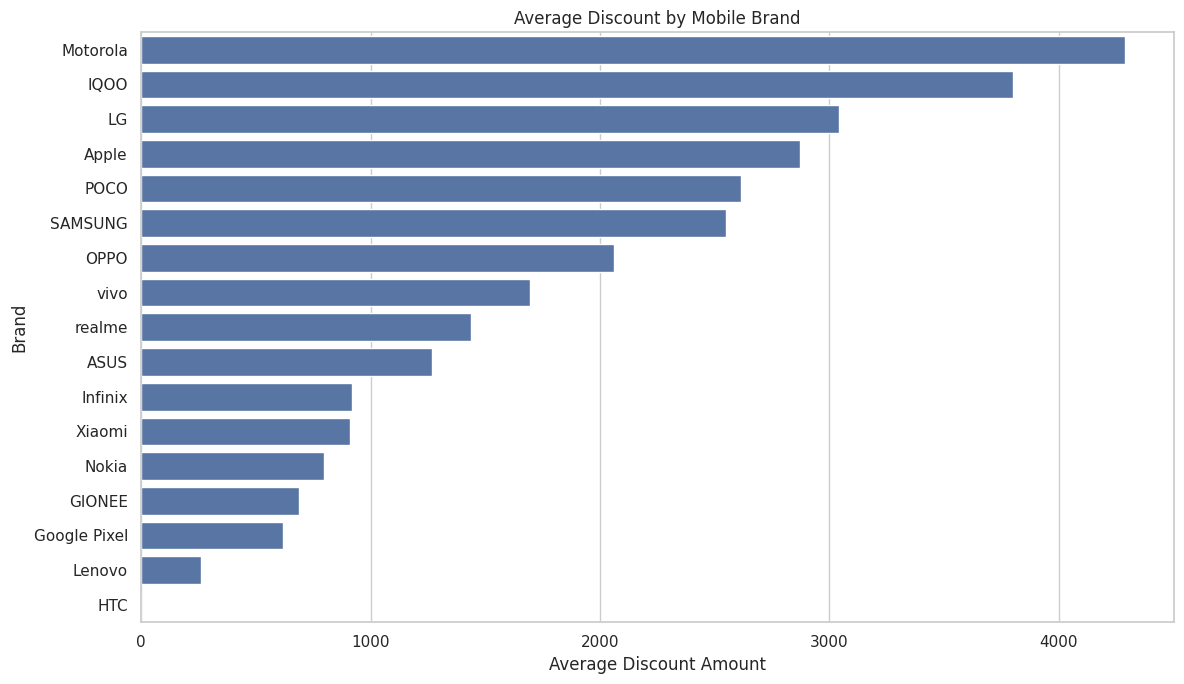

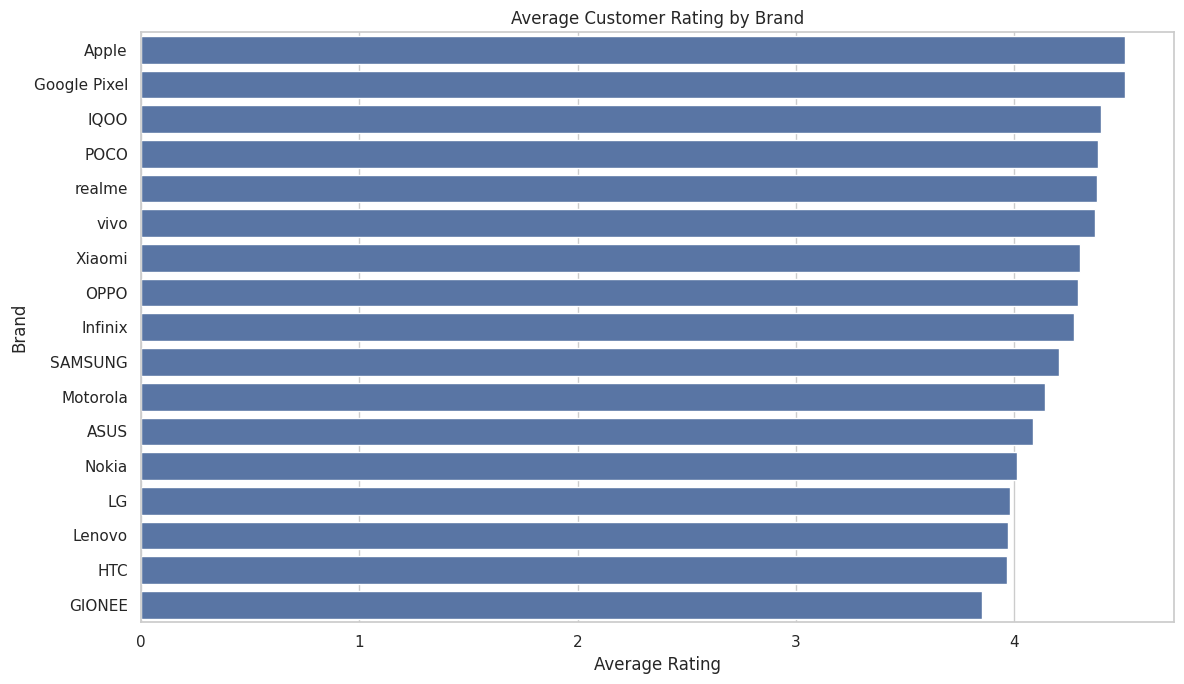

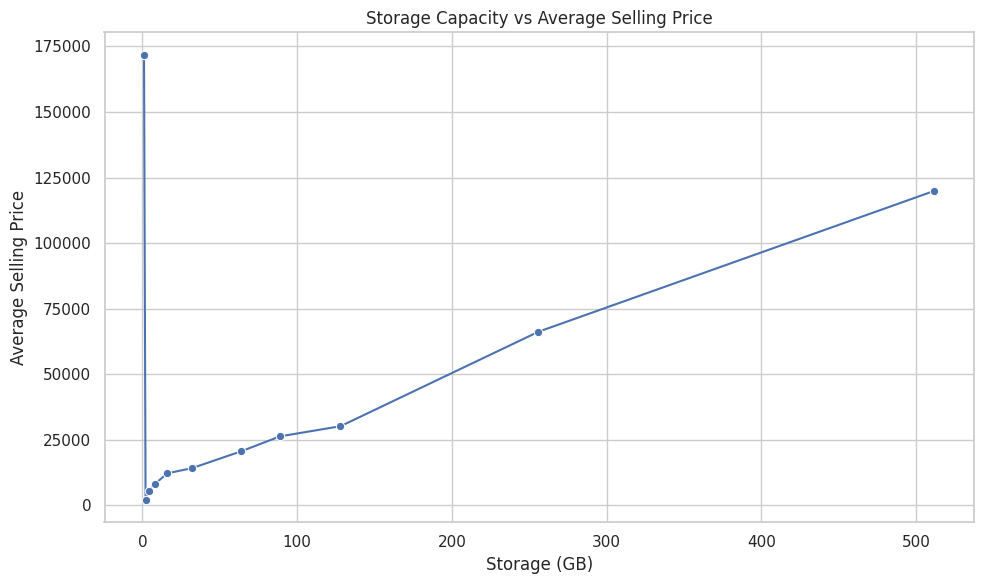

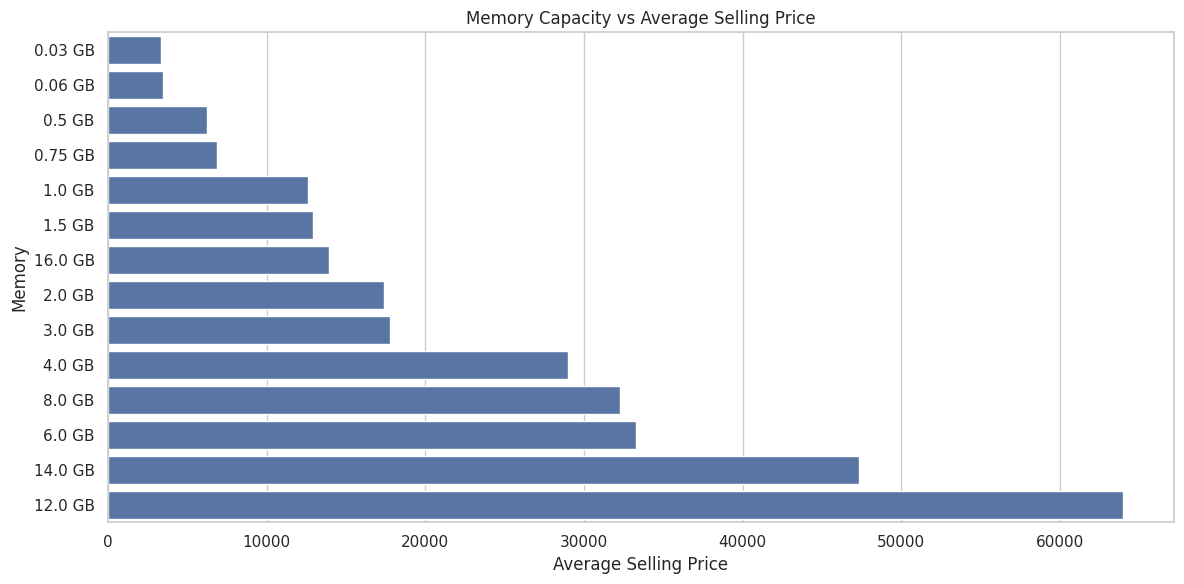

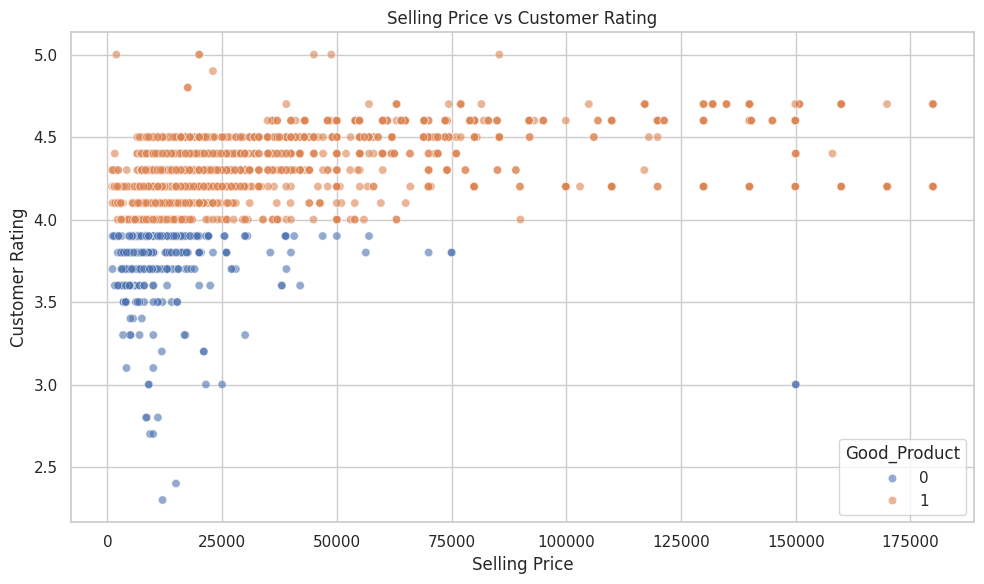

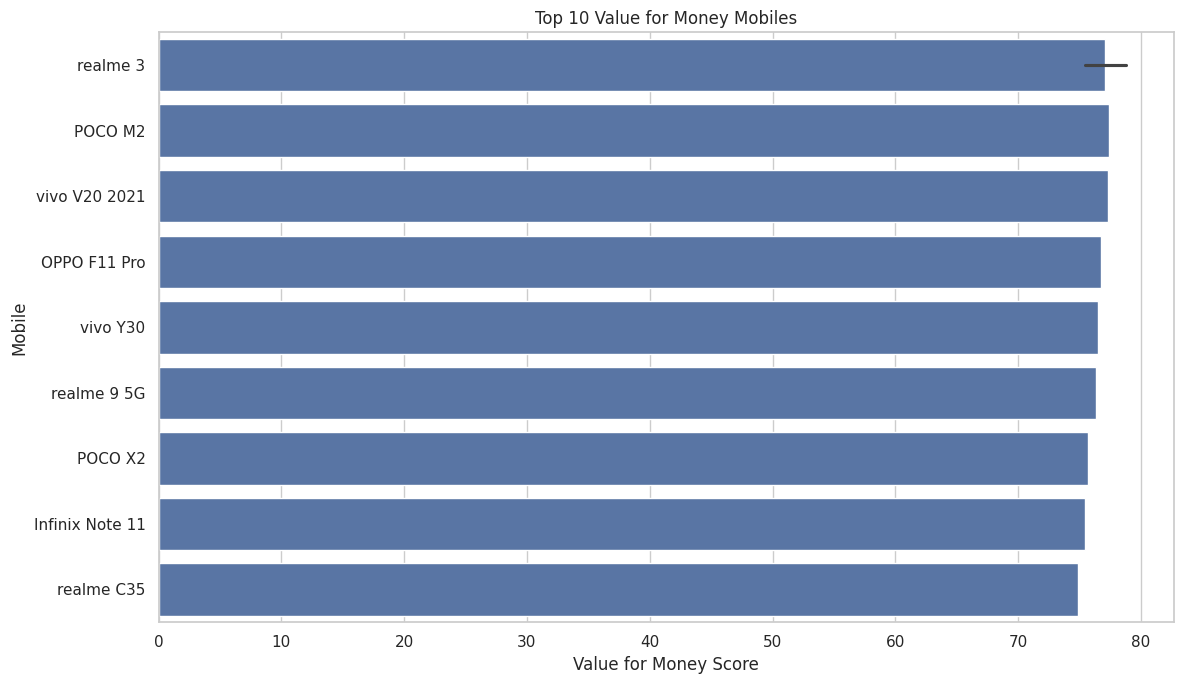

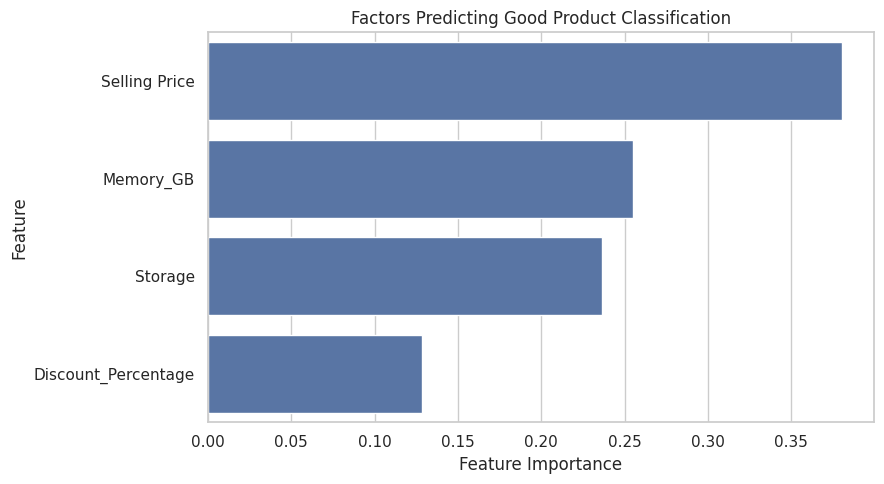

In [18]:
# ==========================================
# VISUALIZATION 1: BRAND-WISE MODEL COUNT
# ==========================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=brand_models,
    x="Total_Models",
    y="Brands"
)

plt.title("Number of Mobile Models by Brand")
plt.xlabel("Number of Unique Models")
plt.ylabel("Mobile Brand")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 2: TOP 10 EXPENSIVE MOBILES
# ==========================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_expensive,
    x="Average_Selling_Price",
    y="Models",
    hue="Brands",
    dodge=False
)

plt.title("Top 10 Expensive Mobile Models")
plt.xlabel("Average Selling Price")
plt.ylabel("Mobile Model")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 3: BRAND-WISE AVERAGE PRICE
# ==========================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=brand_price,
    x="Average_Selling_Price",
    y="Brands"
)

plt.title("Average Selling Price by Brand")
plt.xlabel("Average Selling Price")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 4: BRAND-WISE DISCOUNT
# ==========================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=brand_discount,
    x="Average_Discount",
    y="Brands"
)

plt.title("Average Discount by Mobile Brand")
plt.xlabel("Average Discount Amount")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 5: BRAND-WISE RATINGS
# ==========================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=brand_rating,
    x="Average_Rating",
    y="Brands"
)

plt.title("Average Customer Rating by Brand")
plt.xlabel("Average Rating")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 6: STORAGE VS PRICE
# ==========================================

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=storage_analysis,
    x="Storage",
    y="Average_Selling_Price",
    marker="o"
)

plt.title("Storage Capacity vs Average Selling Price")
plt.xlabel("Storage (GB)")
plt.ylabel("Average Selling Price")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 7: MEMORY VS PRICE
# ==========================================

memory_analysis = mobile.groupby(
    "Memory_Category"
).agg(

    Average_Price=("Selling Price", "mean"),

    Total_Mobiles=("Models", "count")

).reset_index()

memory_analysis = memory_analysis[
    memory_analysis["Total_Mobiles"] >= 5
].copy()

memory_analysis = memory_analysis.sort_values(
    "Average_Price"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=memory_analysis,
    x="Average_Price",
    y="Memory_Category"
)

plt.title("Memory Capacity vs Average Selling Price")
plt.xlabel("Average Selling Price")
plt.ylabel("Memory")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 8: PRICE VS CUSTOMER RATING
# ==========================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=mobile,
    x="Selling Price",
    y="Rating",
    hue="Good_Product",
    alpha=0.6
)

plt.title("Selling Price vs Customer Rating")
plt.xlabel("Selling Price")
plt.ylabel("Customer Rating")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 9: VALUE FOR MONEY TOP 10
# ==========================================

plt.figure(figsize=(12, 7))

plot_data = top_10_value.copy()

plot_data["Mobile_Name"] = (
    plot_data["Brands"] + " " +
    plot_data["Models"]
)

sns.barplot(
    data=plot_data,
    x="VFM_Score",
    y="Mobile_Name"
)

plt.title("Top 10 Value for Money Mobiles")
plt.xlabel("Value for Money Score")
plt.ylabel("Mobile")

plt.tight_layout()
plt.show()


# ==========================================
# VISUALIZATION 10: FEATURE IMPORTANCE
# ==========================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Factors Predicting Good Product Classification")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()